In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [2]:
uploaded = files.upload()
image_path = next(iter(uploaded))

Saving eagle.png to eagle.png


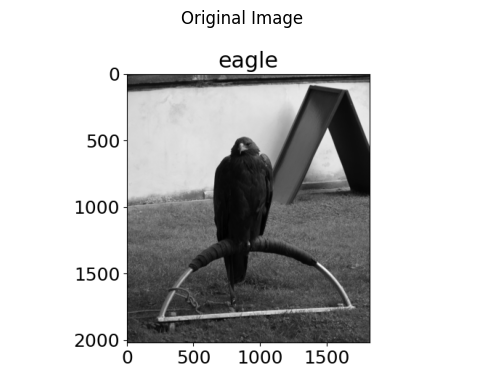

In [3]:
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Could not read the image. Upload a PNG or JPG file.")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

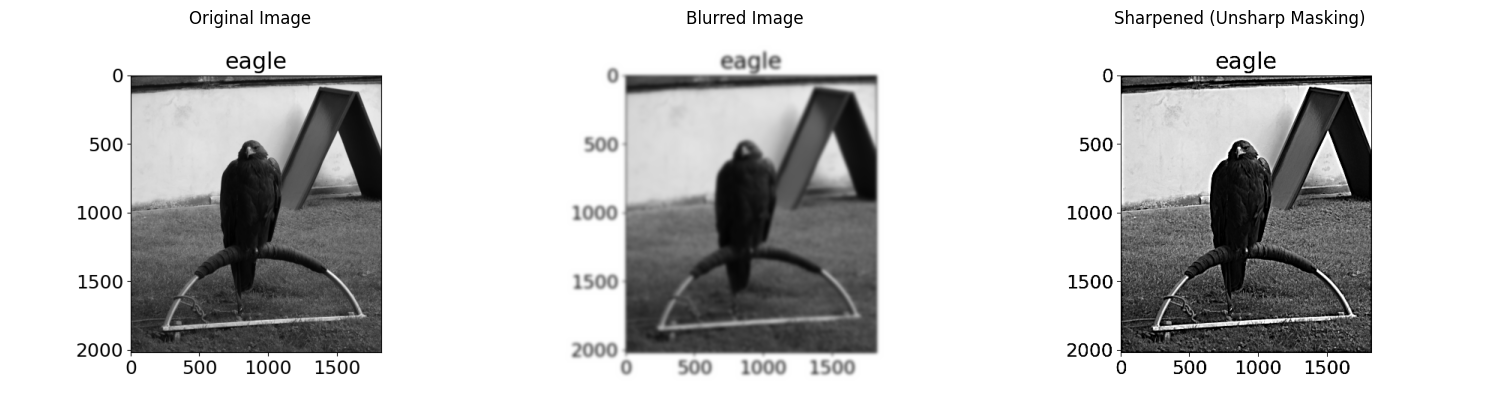

In [6]:
sigma = 2
amount = 1.5
image_float = image.astype(np.float32) / 255.0

blurred = cv2.GaussianBlur(
    image_float, (0, 0), sigmaX=sigma, sigmaY=sigma
)

sharpened = np.clip(
    image_float + amount * (image_float - blurred), 0, 1
)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(image)
ax[0].set_title("Original Image")

ax[1].imshow(blurred)
ax[1].set_title("Blurred Image")

ax[2].imshow(sharpened)
ax[2].set_title("Sharpened (Unsharp Masking)")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

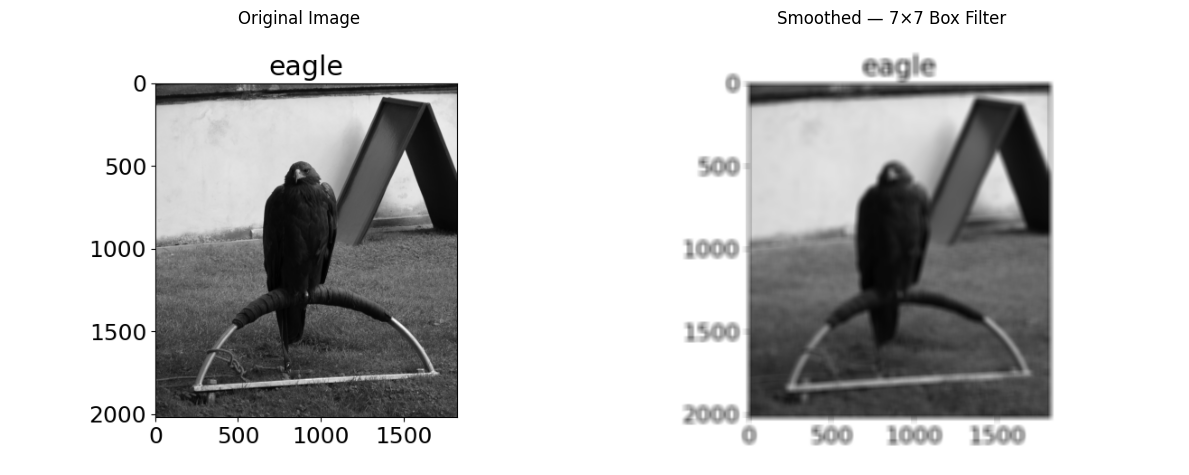

In [7]:
box_kernel = np.ones((7, 7), dtype=np.float32) / 49
smoothed = cv2.filter2D(image, -1, box_kernel)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(smoothed)
ax[1].set_title("Smoothed — 7×7 Box Filter")
ax[1].axis("off")

plt.tight_layout()
plt.show()


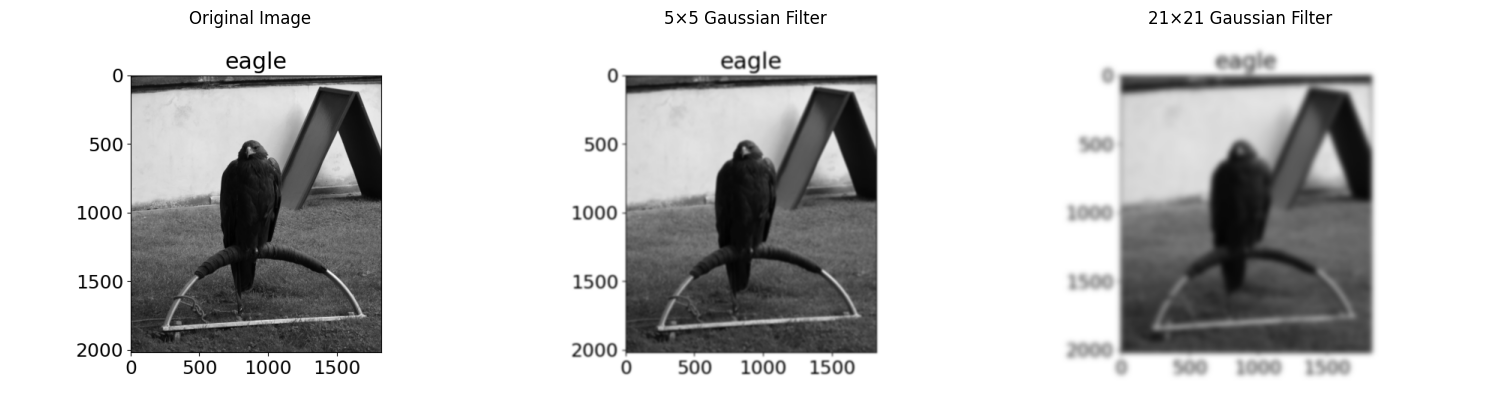

In [8]:
gaussian_5 = cv2.GaussianBlur(image, (5, 5), sigmaX=0)
gaussian_21 = cv2.GaussianBlur(image, (21, 21), sigmaX=0)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(image)
ax[0].set_title("Original Image")

ax[1].imshow(gaussian_5)
ax[1].set_title("5×5 Gaussian Filter")

ax[2].imshow(gaussian_21)
ax[2].set_title("21×21 Gaussian Filter")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

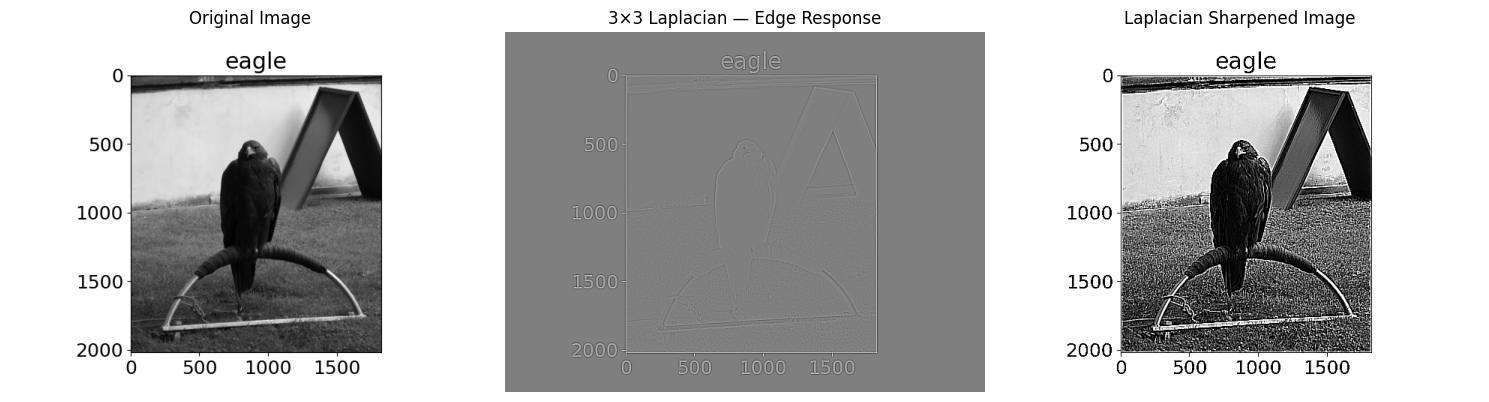

In [9]:
image_float = image.astype(np.float32) / 255.0

laplacian = cv2.Laplacian(
    image_float, cv2.CV_32F, ksize=3
)

sharpened_laplacian = np.clip(
    image_float - laplacian, 0, 1
)

max_abs = np.max(np.abs(laplacian))
laplacian_display = (
    0.5 + laplacian / (2 * max_abs)
    if max_abs > 0
    else np.full_like(laplacian, 0.5)
)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(image)
ax[0].set_title("Original Image")

ax[1].imshow(laplacian_display)
ax[1].set_title("3×3 Laplacian — Edge Response")

ax[2].imshow(sharpened_laplacian)
ax[2].set_title("Laplacian Sharpened Image")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()